In [1]:
try:
    import xgboost as xgb
except:
    !uv pip install -q xgboost
    import xgboost as xgb

print(f"xgboost version: {xgb.__version__}")

xgboost version: 3.4.1


In [2]:
## -- System dependencies --
import sys, os, gc
import torch

## -- Device-Agnostic (GPU/CPU) --
def get_system_info():
    if torch.cuda.is_available():
        return f"GPU: {torch.cuda.get_device_name(0)}"
    else:
        return f"CPU: {os.cpu_count()}"

get_system_info()

'GPU: Tesla T4'

In [3]:
try:
    from colorama import Fore, Style
except:
    !pip install -q colorama
    from colorama import Fore, Style

%matplotlib inline
%config InlineBackend.figure_format = 'svg'

In [4]:
## -- Data Manipulation --
import numpy as np, pandas as pd, random

## -- Visualization --
from IPython.display import display, Image
import matplotlib.pyplot as plt
import seaborn as sns

## -- Functional Tools --
import itertools
from tqdm.auto import tqdm
from time import time, sleep

## -- Machine Learning --
from sklearn.calibration import CalibrationDisplay
from sklearn.preprocessing import KBinsDiscretizer, TargetEncoder as skTE
from sklearn.metrics import roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.model_selection import StratifiedKFold, train_test_split, cross_val_score
from sklearn.ensemble import HistGradientBoostingClassifier

import warnings
warnings.simplefilter('ignore')
warnings.filterwarnings('ignore')

## -- Global Settings --
# sklearn.set_config(transform_output='pandas')

# pd.options.mode.copy_on_write = True
pd.set_option('display.max_columns', 100)
# sns.set_style("whitegrid")
# plt.style.use('ggplot')

In [5]:
TEAL, GOLD, CORAL, BLUE, DARK, CRIM, MUTED, INK, PAPER = '#168c91','#e8b44f','#dc705a',\
                                                         'dodgerblue','#0B4F7A','crimson',\
                                                         '#627D98','#102A43','#faf9f5'
plt.rcParams.update({
    'figure.facecolor': PAPER,
    'axes.facecolor': PAPER,
    'savefig.facecolor': PAPER,
    'font.family': 'DejaVu Sans',
    'font.size': 8,
    'axes.titlesize': 11,
    'axes.titleweight': 'semibold',
    'axes.labelcolor': INK,
    'text.color': INK,
    'xtick.color': DARK,
    'ytick.color': DARK,
    'axes.edgecolor': MUTED,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.color': MUTED,
    'patch.edgecolor': DARK,
    # 'patch.force_edgecolor': True,
    # 'patch.linewidth': 1.5,
    # 'figure.dpi':110,
    # 'savefig.dpi':160,
})
# CMAP = LinearSegmentedColormap.from_list('atlas', ['#f0f5ef','#a9d6ca',TEAL,INK])
# sns.set_palette([TEAL, GOLD, CORAL, BLUE, MUTED, CRIM, DARK, INK, PAPER])

## -- Set Global Seed --
CFG = {
    'FOLDS':  5,
    'SEED':   42,
    'GREEN':  '\033[32m',
    'YELLOW': '\033[33m',
    'RESET':  '\033[0m'
}

print(f"CLASSIC {CFG['GREEN']} GREEN {CFG['RESET']} {CFG['YELLOW']} YELLOW {CFG['RESET']}")

CLASSIC  GREEN   YELLOW 


In [6]:
## -- ⚠️ IMPORTANT: SELECT PLATFORM ⚠️ --
PLATFORM = "kaggle" # -> 'colab' 'kaggle'

if PLATFORM == "kaggle":
    PATH   = "/kaggle/input/competitions/playground-series-s6e11/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    ORIG_PATH = "/kaggle/input/datasets/uditjain13/credit-card-fraud-detection-2026/"
    orig = pd.read_csv(ORIG_PATH+"credit_card_fraud_2026.csv")
elif PLATFORM == "colab":
    from google.colab import drive
    drive.mount("/content/drive")
    PATH   = "/content/drive/MyDrive/-- shared_notebooks --/Ps6e11 | Credit Card Fraud/_fraud_data/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    orig   = pd.read_csv(PATH+"credit_card_fraud_2026.csv")
    
## =================================================================================

ID = 'id'
TARGET = 'is_fraud'

cat_cols = train.drop([ID, TARGET], axis=1).select_dtypes(include=['object', 'bool']).columns.tolist()
num_cols = train.drop([ID, TARGET], axis=1).select_dtypes(exclude=['object', 'bool']).columns.tolist()
base_cols = cat_cols + num_cols

for (name, df) in {"Train": train, "Test": test, 'Orig': orig}.items(): #
    print(f"{name} shape: {df.shape}")

train.head()

Train shape: (699960, 26)
Test shape: (299984, 25)
Orig shape: (20000, 26)


,id,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,is_fraud
0,0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,0.0
1,1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,0.0
2,2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,0.0
3,3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,0.0
4,4,653.85,0.80,4,11.69,37,52,3291.06,0,34.8,4,4,48.0,0,Electronics,Visa,3D Secure,Online,Windows PC,False,False,False,False,False,False,0.0


In [7]:
train_len = len(train)
test_len  = len(test)

float_cols = [
    'amount_usd', 'account_balance_usd',
    'hours_since_last_txn', 'distance_from_home_km',
    'velocity_score', 'merchant_risk_score',
]

float_small = [
    'hours_since_last_txn', 'distance_from_home_km',
    'velocity_score', 'merchant_risk_score',
]

float_large = [
    'amount_usd', 'account_balance_usd',
]

int_cols = [
    'customer_age', 'card_age_months', 'time_of_day_hour', 'txn_count_last_24h',
    'cvv_retry_count', 'day_of_week', 'prior_disputes',
]

int_small = ['txn_count_last_24h', 'cvv_retry_count', 'day_of_week', 'prior_disputes']
int_large = ['card_age_months', 'customer_age', 'time_of_day_hour']

n_unique = train.nunique().sort_values()
n_unique

is_new_merchant                      2
is_fraud                             2
is_ai_generated_scam_attempt         2
billing_shipping_mismatch            2
ip_country_mismatch                  2
used_vpn                             2
is_foreign_transaction               2
cvv_retry_count                      4
auth_method                          5
prior_disputes                       5
card_type                            5
channel                              5
day_of_week                          7
device_type                          8
txn_count_last_24h                  12
merchant_category                   12
time_of_day_hour                    24
card_age_months                     49
customer_age                        64
velocity_score                     666
merchant_risk_score                950
hours_since_last_txn              3633
distance_from_home_km             4365
amount_usd                       13387
account_balance_usd              43317
id                       

In [8]:
# import pandas as pd
# from pandas.util import hash_pandas_object

# # Generate hashes
# hash1 = hash_pandas_object(train[base_cols], index=False)
# hash2 = hash_pandas_object(orig[base_cols], index=False)

# # Find rows in orig that are NOT present in train
# new_or_changed_rows = hash2.isin(hash1)

# # Get the actual data for those mismatched rows
# mismatched_orig_data = orig[new_or_changed_rows]
# display(mismatched_orig_data)

In [9]:
## -- Groupby features FE -- ⚠️
from typing import List, Optional, Sequence
from sklearn.base import BaseEstimator, TransformerMixin

class GroupbyAggregator(BaseEstimator, TransformerMixin):
    """
    Leak-free groupby feature generator for CV folds and multiple test sets.
    Fits aggregations on training data only and left-joins them onto any DataFrame.
    """

    def __init__(
        self,
        grouper: str,
        agg_cols: List[str],
        aggs: Sequence[str] = ("mean", "std"),
    ):
        self.grouper = grouper
        self.agg_cols = [c for c in agg_cols if c != grouper]
        self.aggs = aggs
        self.stats_: Optional[pd.DataFrame] = None
        self.group_cols_: List[str] = []

    def fit(self, X: pd.DataFrame, y: Optional[pd.Series] = None) -> "GroupbyAggregator":
        """Compute group aggregations strictly on X (e.g., X_train_fold)."""
        target_cols = [col for col in self.agg_cols if col != self.grouper]
        if not target_cols:
            self.stats_ = None
            self.group_cols_ = []
            return self

        prefix = self.grouper.split("_")[0]
        stats = X.groupby(self.grouper, observed=False)[target_cols].agg(list(self.aggs))

        # Flatten MultiIndex columns into clean feature names
        self.group_cols_ = [
            f"{col}_{prefix}_GROUPBY_{agg}".replace(" ", "")
            for col, agg in stats.columns
        ]
        stats.columns = self.group_cols_
        self.stats_ = stats
        return self

    def transform(self, X: pd.DataFrame) -> pd.DataFrame:
        """Map learned group statistics onto X while preserving its original index."""
        if self.stats_ is None or not self.group_cols_:
            return X.copy()

        # Left merge preserves row order; re-assign original index to prevent resets
        merged = X.merge(self.stats_, on=self.grouper, how="left")
        merged.index = X.index
        return merged

    def transform_many(self, *dfs: pd.DataFrame) -> List[pd.DataFrame]:
        """Convenience helper to transform multiple DataFrames in a single call."""
        return [self.transform(df) for df in dfs]


In [10]:
from sklearn.base import BaseEstimator, TransformerMixin ## ===== Target/Category Mean ENCODERS =====

class customTE(BaseEstimator, TransformerMixin):
    """
    Target Encoder that supports multiple aggregation functions,
    internal cross-validation for leakage prevention, and smoothing.

    Parameters
    ----------
    cols_to_encode : list of str
        List of column names to be target encoded.

    aggs : list of str, default=['mean']
        List of aggregation functions to apply. Any function accepted by
        pandas' `.agg()` method is supported, such as:
        'mean', 'std', 'var', 'min', 'max', 'skew', 'nunique',
        'count', 'sum', 'median'.
        Smoothing is applied only to the 'mean' aggregation.

    cv : int, default=5
        Number of folds for cross-validation in fit_transform.

    smooth : float or 'auto', default='auto'
        The smoothing parameter `m`. A larger value puts more weight on the
        global mean. If 'auto', an empirical Bayes estimate is used.

    drop_original : bool, default=False
        If True, the original columns to be encoded are dropped.
    """
    def __init__(self, cols_to_encode, aggs=['mean'], cv=5, smooth='auto', drop_original=False):
        self.cols_to_encode = cols_to_encode
        self.aggs = aggs
        self.cv = cv
        self.smooth = smooth
        self.drop_original = drop_original
        self.mappings_ = {}
        self.global_stats_ = {}

    def fit(self, X, y):
        """
        Learn mappings from the entire dataset.
        These mappings are used for the transform method on validation/test data.
        """
        temp_df = X.copy()
        temp_df['target'] = y

        # Learn global statistics for each aggregation
        for agg_func in self.aggs:
            self.global_stats_[agg_func] = y.agg(agg_func)

        # Learn category-specific mappings
        for col in self.cols_to_encode:
            self.mappings_[col] = {}
            for agg_func in self.aggs:
                mapping = temp_df.groupby(col)['target'].agg(agg_func)
                self.mappings_[col][agg_func] = mapping

        return self

    def transform(self, X):
        """
        Apply learned mappings to the data.
        Unseen categories are filled with global statistics.
        """
        X_transformed = X.copy()
        for col in self.cols_to_encode:
            for agg_func in self.aggs:
                new_col_name = f'TE_{col}_{agg_func}'
                map_series = self.mappings_[col][agg_func]
                X_transformed[new_col_name] = X[col].map(map_series)
                X_transformed[new_col_name].fillna(self.global_stats_[agg_func], inplace=True)

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed

    def fit_transform(self, X, y):
        """
        Fit and transform the data using internal cross-validation to prevent leakage.
        """
        # First, fit on the entire dataset to get global mappings for transform method
        self.fit(X, y)

        # Initialize an empty DataFrame to store encoded features
        encoded_features = pd.DataFrame(index=X.index)

        kf = KFold(n_splits=self.cv, shuffle=True, random_state=42)

        for train_idx, val_idx in kf.split(X, y):
            X_trn, y_trn = X.iloc[train_idx], y.iloc[train_idx]
            X_val = X.iloc[val_idx]

            temp_df_train = X_trn.copy()
            temp_df_train['target'] = y_trn

            for col in self.cols_to_encode:
                # --- Calculate mappings only on the training part of the fold ---
                for agg_func in self.aggs:
                    new_col_name = f'TE_{col}_{agg_func}'

                    # Calculate global stat for this fold
                    fold_global_stat = y_trn.agg(agg_func)

                    # Calculate category stats for this fold
                    mapping = temp_df_train.groupby(col)['target'].agg(agg_func)

                    # --- Apply smoothing only for 'mean' aggregation ---
                    if agg_func == 'mean':
                        counts = temp_df_train.groupby(col)['target'].count()

                        m = self.smooth
                        if self.smooth == 'auto':
                            # Empirical Bayes smoothing
                            variance_between = mapping.var()
                            avg_variance_within = temp_df_train.groupby(col)['target'].var().mean()
                            if variance_between > 0:
                                m = avg_variance_within / variance_between
                            else:
                                m = 0  # No smoothing if no variance between groups

                        # Apply smoothing formula
                        smoothed_mapping = (counts * mapping + m * fold_global_stat) / (counts + m)
                        encoded_values = X_val[col].map(smoothed_mapping)
                    else:
                        encoded_values = X_val[col].map(mapping)

                    # Store encoded values for the validation fold
                    encoded_features.loc[X_val.index, new_col_name] = encoded_values.fillna(fold_global_stat)

        # Merge with original DataFrame
        X_transformed = X.copy()
        for col in encoded_features.columns:
            X_transformed[col] = encoded_features[col]

        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)

        return X_transformed


class CategoryMeanTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols=None):
        self.cat_cols = cat_cols
        self.mappings_ = {}
    def fit(self, X, y):
        X = X.copy()
        if self.cat_cols is None:
            self.cat_cols = X.select_dtypes(include=['category']).columns.tolist()
        self.mappings_ = {}
        for col in self.cat_cols:
            df_temp = pd.DataFrame({col: X[col], 'y': y})
            group_means = df_temp.groupby(col, dropna=False)['y'].mean()
            sorted_categories = group_means.sort_values().index
            self.mappings_[col] = {cat: i for i, cat in enumerate(sorted_categories)}

        return self

    def transform(self, X, y=None):
        X = X.copy()
        for col, mapping in self.mappings_.items():
            if col in X.columns:
                X[col] = X[col].map(mapping)

        return X

In [11]:
## -- original_TE with factorization --
from typing import List, Optional, Tuple

def original_fcTE(
    orig: pd.DataFrame,
    df: pd.DataFrame,
    features: Optional[List[str]] = None,
    target: Optional[str] = None,
    aggs: Optional[List[str]] = None,
    fill_nan: bool = False,
) -> Tuple[pd.DataFrame, List[str]]:
    """
    Applies out-of-fold / external dataset target encoding (TE) from `orig` onto `df`.
    """
    X_df = df.copy()
    orig_df = orig.copy()  # Prevent mutating the caller's original DataFrame

    # 1. Early exit with consistent return signature (DataFrame, list)
    if not features or not aggs or target is None:
        return X_df, []

    if target not in orig_df.columns:
        raise ValueError(f"Target column '{target}' not found in `orig`.")

    # 2. Validate features exist in BOTH DataFrames
    valid_features = [
        col for col in features 
        if col in orig_df.columns and col in X_df.columns
    ]
    
    # Separate 'count' from target-dependent aggregations
    supported_target_aggs = {'mean', 'median', 'nunique', 'std', 'skew', 'max', 'min'}
    clean_aggs = [a.lower() for a in aggs]

    orig_cols = []
    new_features_dict = {}

    for col in tqdm(valid_features, desc="original_augmenting"):
        # Align categorical/object/bool dtypes safely only for needed columns
        if pd.api.types.is_object_dtype(X_df[col]) or \
           isinstance(X_df[col].dtype, pd.CategoricalDtype) or \
           pd.api.types.is_bool_dtype(X_df[col]):
            combined = pd.concat([X_df[col], orig_df[col]], ignore_index=True)
            codes, _ = pd.factorize(combined, sort=True)
            X_df[col] = codes[:len(X_df)]
            orig_df[col] = codes[len(X_df):]

        # Group once per feature instead of once per (feature, agg)
        grouped = orig_df.groupby(col, dropna=False)
        
        # Compute target aggregations in one vectorized pass
        target_aggs_to_run = [a for a in clean_aggs if a in supported_target_aggs]
        if target_aggs_to_run:
            try:
                agg_stats = grouped[target].agg(target_aggs_to_run)
                for agg_key in target_aggs_to_run:
                    new_col = f"oTE_{col}_{agg_key}"
                    # .map() preserves X_df's exact index and row order
                    new_features_dict[new_col] = X_df[col].map(agg_stats[agg_key])
                    orig_cols.append(new_col)
            except Exception as e:
                print(f"Warning: failed target aggs for col={col}: {e}")

        # Handle 'count' separately since it doesn't depend on `target`
        if 'count' in clean_aggs:
            new_col = f"oTE_{col}_count"
            counts = grouped.size()
            new_features_dict[new_col] = X_df[col].map(counts)
            orig_cols.append(new_col)

    # Concatenate all new columns at once to avoid DataFrame fragmentation
    if new_features_dict:
        new_cols_df = pd.DataFrame(new_features_dict, index=X_df.index)
        X_df = pd.concat([X_df, new_cols_df], axis=1)

    # 3. Fill missing values cleanly
    if fill_nan and orig_cols:
        global_mean = orig_df[target].mean()
        global_median = orig_df[target].median()

        fill_values = {}
        for c in orig_cols:
            if c.endswith(('_mean', '_max', '_min')):
                fill_values[c] = global_mean
            elif c.endswith('_median'):
                fill_values[c] = global_median
            else:
                fill_values[c] = 0

        X_df = X_df.fillna(value=fill_values)

    return X_df, orig_cols

print('-- Factorized augment function ready! --')

-- Factorized augment function ready! --


In [12]:
## -- original_TE with objects --
from typing import List, Optional, Tuple

def original_obTE(
    orig: pd.DataFrame,
    df: pd.DataFrame,
    features: Optional[List[str]] = None,
    target: Optional[str] = None,
    aggs: Optional[List[str]] = None,
    fill_nan: bool = False,
) -> Tuple[pd.DataFrame, List[str]]:
    """
    Applies external dataset target encoding (TE) from `orig` onto `df`
    while preserving original categorical/string dtypes.
    """
    X_df = df.copy()

    if not features or not aggs or target is None:
        return X_df, []

    if target not in orig.columns:
        raise ValueError(f"Target column '{target}' not found in `orig`.")

    valid_features = [
        col for col in features 
        if col in orig.columns and col in X_df.columns
    ]
    
    supported_target_aggs = {'mean', 'median', 'nunique', 'std', 'skew', 'max', 'min'}
    clean_aggs = [a.lower() for a in aggs]

    orig_cols = []
    new_features_dict = {}

    for col in tqdm(valid_features, desc="original_augmenting"):
        # Group directly on raw strings, objects, or categories (observed=True prevents cartesian blowups)
        grouped = orig.groupby(col, dropna=False, observed=True)
        
        target_aggs_to_run = [a for a in clean_aggs if a in supported_target_aggs]
        if target_aggs_to_run:
            try:
                agg_stats = grouped[target].agg(target_aggs_to_run)
                for agg_key in target_aggs_to_run:
                    new_col = f"oTE_{col}_{agg_key}"
                    # Convert Series to plain dict so CategoricalIndex mismatches don't cause issues
                    mapping_dict = agg_stats[agg_key].to_dict()
                    new_features_dict[new_col] = X_df[col].map(mapping_dict).astype('float32')
                    orig_cols.append(new_col)
            except Exception as e:
                print(f"Warning: failed target aggs for col={col}: {e}")

        if 'count' in clean_aggs:
            new_col = f"oTE_{col}_count"
            counts_dict = grouped.size().to_dict()
            new_features_dict[new_col] = X_df[col].map(counts_dict).astype('float32')
            orig_cols.append(new_col)

    if new_features_dict:
        new_cols_df = pd.DataFrame(new_features_dict, index=X_df.index)
        X_df = pd.concat([X_df, new_cols_df], axis=1)

    if fill_nan and orig_cols:
        global_mean = orig[target].mean()
        global_median = orig[target].median()

        fill_values = {}
        for c in orig_cols:
            if c.endswith(('_mean', '_max', '_min')):
                fill_values[c] = global_mean
            elif c.endswith('_median'):
                fill_values[c] = global_median
            else:
                fill_values[c] = 0

        X_df = X_df.fillna(value=fill_values)

    return X_df, orig_cols

print('-- Object augment function ready! --')

-- Object augment function ready! --


## FEATURE ENGINEERING

In [13]:
## -- NUMS_to_CATS (TargetEncoding) -- ⚠️

FEATURES = [c for c in train.columns if c not in [ID, TARGET]]
print("Features before operation:", len(FEATURES))

combined = pd.concat([train, test], ignore_index=True)
## ------------------------------------------------------------
## -- Duplicate Nums as Cats --
nums_to_cats = []
select_nc = num_cols

for c in tqdm(select_nc, desc="nums_to_cats"):
    new_cat = f"{c}_cat_"
    combined[new_cat], unique = pd.factorize(combined[c], sort=True)
    # combined[new_cat] = combined[new_cat].astype('int32') #.astype('category')
    nums_to_cats.append(new_cat)
## ------------------------------------------------------------
train = combined.iloc[:train_len]
test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
# orig  = combined.iloc[train_len+test_len:]

del combined
print("Features after operation:", train.shape[1])

Features before operation: 24


nums_to_cats:   0%|          | 0/13 [00:00<?, ?it/s]

Features after operation: 39


In [14]:
# ## -- Frequency encoding -- ⚠️
# combined = pd.concat([train, test], ignore_index=True)

# freq_cols = []
# select_freq = base_cols

# print("\nCreating frequencies (Safe Global Mapping)...")
# for col in select_freq:
#     n = f"{col}_FREQ_"
#     # print(f"⧗ {n}", end="")

#     # Calculate frequencies using ONLY train
#     freq_map = train[col].value_counts(dropna=False, normalize=False).to_dict()

#     # Map the training-derived frequencies across all datasets safely
#     train[n] = train[col].map(freq_map).astype("float32")
#     test[n]  = test[col].map(freq_map).astype("float32")
#     orig[n]  = orig[col].map(freq_map).astype("float32")
    
#     freq_cols.append(n)
#     # print()

# print(f"\n *** Total frequency features: {len(freq_cols)}")
# train[freq_cols].nunique()

In [15]:
# ## -- DIGITS extraction -- ⚠️

# FEATURES = [c for c in train.columns if c not in [ID, TARGET]]

# combined = pd.concat([train, test], ignore_index=True)
# digit_cols = []

# for col in num_cols:
#     scaled = np.rint(combined[col].fillna(0) * 10**4).astype("int64")
#     for k in range(-2, 3):
#         dig_col = f"{col}_DIGIT_{k}"
#         combined[dig_col] = (scaled // 10**(k+4) % 10).astype('int8') # .astype('category')
#         digit_cols.append(dig_col)

# train = combined.iloc[:train_len]
# test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
# # orig = combined.iloc[train_len+test_len:]

# # Check nunique, and find which ones are < 2
# unique_counts = train[digit_cols].nunique()
# drop_cols = unique_counts[unique_counts < 2].index.tolist()

# # update digit cols for keep
# digit_cols = [i for i in set(digit_cols) if i not in set(drop_cols)]

# # drop constant features
# train = train.drop(columns=drop_cols)
# test  = test.drop(columns=drop_cols)
# # orig  = orig.drop(columns=drop_cols)

# del combined
# print(f"Total digit features: {len(digit_cols)}\n")

# train[digit_cols].nunique()

In [16]:
# # ## -- Ai suggest: DIGITS extraction -- ⚠️
# combined = pd.concat([train, test, orig], ignore_index=True)
# new_digits = {}

# for col in num_cols:
#     is_na = combined[col].isna()
#     scaled = np.rint(np.abs(combined[col].fillna(0)) * 10**4).astype("int64")
    
#     for k in range(-2, 3):
#         dig_col = f"{col}_DIGIT_{k}"
#         digits = ((scaled // 10**(k + 4)) % 10).astype("int8")
#         digits[is_na] = -1
#         new_digits[dig_col] = digits

# digit_df = pd.DataFrame(new_digits, index=combined.index)

# # Filter constant features based ONLY on train
# train_digits = digit_df.iloc[:train_len]
# unique_counts = train_digits.nunique()
# keep_cols = unique_counts[unique_counts >= 2].index.tolist()

# digit_df = digit_df[keep_cols]

# # Re-attach cleanly without slicing bugs or SettingWithCopyWarning
# train = pd.concat([train.reset_index(drop=True), digit_df.iloc[:train_len].reset_index(drop=True)], axis=1)
# test = pd.concat([test.reset_index(drop=True), digit_df.iloc[train_len:train_len + test_len].reset_index(drop=True)], axis=1)
# orig = pd.concat([orig.reset_index(drop=True), digit_df.iloc[train_len + test_len:].reset_index(drop=True)], axis=1)

# del combined, digit_df, new_digits
# print(f"Total digit features: {len(keep_cols)}\n")
# print(train[keep_cols].nunique())

In [17]:
def digit_keys(df1, cols=float_cols):
    df = df1.copy()
    """How each number is written: six label-free keys per float column."""
    keys = {}
    for c in cols:
        units = np.rint(df[c].to_numpy() * 100).astype(np.int64)        # 1371.37 -> 137137
        integer = units // 100
        s = pd.Series(integer).astype(str)
        keys[f"{c}__int"] = integer                                      # 1371
        keys[f"{c}__int10"] = units // 1000                              # 137
        keys[f"{c}__tenths"] = units // 10                               # 13713
        keys[f"{c}__cents"] = units % 100                                # 37
        keys[f"{c}__lead1"] = (s.str.len() * 10 + s.str[0].astype(int)).to_numpy()     # 4|1
        keys[f"{c}__lead2"] = (s.str.len() * 100 + s.str[:2].astype(int)).to_numpy()   # 4|13

    new_df = pd.DataFrame(keys, index=df.index)
    full_df = pd.concat([df, new_df], axis=1)
    return full_df, [*keys.keys()]

train, digit_cols2 = digit_keys(train)
test, _ = digit_keys(test)
orig, _ = digit_keys(orig)

print(train.shape, test.shape)
train[digit_cols2].nunique()

(699960, 75) (299984, 74)


amount_usd__int                   1144
amount_usd__int10                  235
amount_usd__tenths                4599
amount_usd__cents                  100
amount_usd__lead1                   33
amount_usd__lead2                  217
account_balance_usd__int          4928
account_balance_usd__int10        1116
account_balance_usd__tenths      19083
account_balance_usd__cents         100
account_balance_usd__lead1          28
account_balance_usd__lead2         196
hours_since_last_txn__int           51
hours_since_last_txn__int10          6
hours_since_last_txn__tenths       502
hours_since_last_txn__cents        100
hours_since_last_txn__lead1         15
hours_since_last_txn__lead2         51
distance_from_home_km__int          56
distance_from_home_km__int10         6
distance_from_home_km__tenths      542
distance_from_home_km__cents       100
distance_from_home_km__lead1        15
distance_from_home_km__lead2        56
velocity_score__int                 73
velocity_score__int10    

In [18]:
# ## -- Arithmetic features --
# combined = pd.concat([train, test], ignore_index=True)

# combined['velocity_+_merchant'] = (combined['velocity_score'] + combined['merchant_risk_score']) / 100.0
# combined['risk_scores_X_cvv'] = combined['velocity_+_merchant'] * combined['cvv_retry_count']

# train = combined.iloc[:train_len]
# test  = combined.iloc[train_len:train_len+test_len].drop(columns=[TARGET])
# # orig  = combined.iloc[train_len+test_len:]

# del combined

# print(f"Arithmetic features created!")

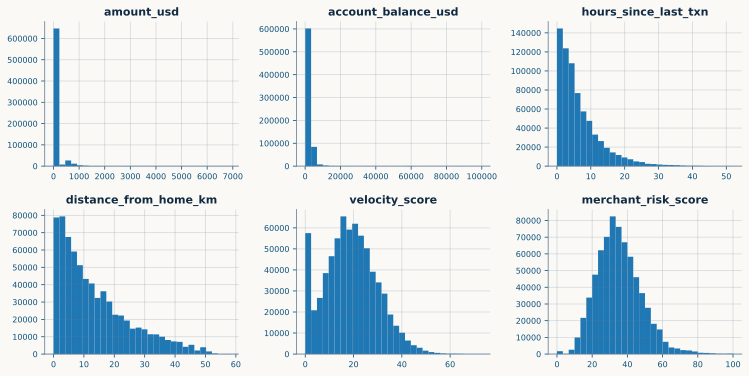

In [19]:
train[float_cols].hist(layout=(2, 3), figsize=(12.5, 6), bins=30)
plt.show()

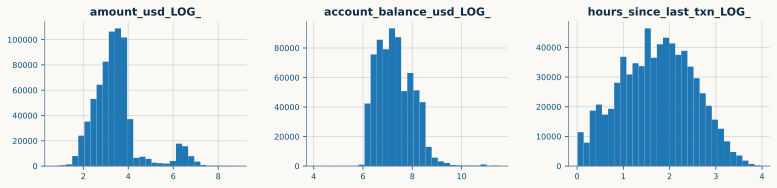

In [20]:
## -- LOG features --
combined = pd.concat([train, test], ignore_index=True)
select_ = ["amount_usd", "account_balance_usd", "hours_since_last_txn"]

log_cols = []
for c in select_:
    log_c = f"{c}_LOG_"
    combined[log_c] = np.log1p(combined[c])
    log_cols.append(log_c)

train = combined.iloc[:train_len]
test  = combined.iloc[train_len:]

train[log_cols].hist(layout=(2, 3), figsize=(13, 6), bins=30)
plt.show()

In [21]:
# ## -- Cyclic encoding --
# cyclic_cols = [] 
# cy_cols = ["hours_since_last_txn", "txn_count_last_24h"]

# for col in tqdm(cy_cols):
#     for p in [12, 24]:
#         n_s = f"{col}_SINE_{p}"
#         train[n_s] = np.sin(2 * np.pi * train[col] / p).astype('float32')
#         test[n_s]  = np.sin(2 * np.pi * test[col] / p).astype('float32')
#         orig[n_s]  = np.sin(2 * np.pi * orig[col] / p).astype('float32')
#         cyclic_cols.append(n_s)

#         n_c = f"{col}_COSINE_{p}"
#         train[n_c] = np.cos(2 * np.pi * train[col] / p).astype('float32')
#         test[n_c]  = np.cos(2 * np.pi * test[col] / p).astype('float32')
#         orig[n_c]  = np.cos(2 * np.pi * orig[col] / p).astype('float32')
#         cyclic_cols.append(n_c)

# print(f"Cylcic Features created: {len(cyclic_cols)}")
# display(train[cyclic_cols].describe().T)

# train[cyclic_cols].head()

In [22]:
# ## -- Feature Interactions -- ⚠️

# INTER = []

# combined = pd.concat([train, test], ignore_index=True)
# # ------------------------------------------------------------------------
# combo_2_1 = list(itertools.combinations(cat_cols, 2))
# for c1, c2 in tqdm(combo_2_1, desc="Pairwise Sync Encoding"):
#     n_col = f"Bi_{c1}_X_{c2}".replace(" ", "")
#     combined[n_col] = combined[c1].astype(str) + "_" + combined[c2].astype(str)
#     combined[n_col], _ = pd.factorize(combined[n_col], sort=True)
#     # combined[n_col] = combined[n_col].astype("category")
#     INTER.append(n_col)

# # combo_3_1 = list(itertools.combinations(cat_cols, 3))
# # for c1, c2, c3 in tqdm(combo_3_1, desc='Triplewise Sync Encoding'):
# #     n_col = f"Tri_{c1}_X_{c2}_X_{c3}".replace(" ", "")
# #     combined[n_col] = combined[c1].astype(str) + "_" + combined[c2].astype(str) + "_" + combined[c3].astype(str)
# #     combined[n_col], _ = pd.factorize(combined[n_col], sort=True)
# #     # combined[n_col] = combined[n_col].astype('category')
# #     INTER.append(n_col)

# # combo_4_1 = list(itertools.combinations(cat_cols, 4))
# # for c1, c2, c3, c4 in tqdm(combo_4_1, desc='Quadwise Sync Encoding'):
# #     n_col = f"Quad_{c1}_X_{c2}_X_{c3}_X_{c4}".replace(" ", "")
# #     combined[n_col] = combined[c1].astype(str) + "_" + combined[c2].astype(str) + "_" + combined[c3].astype(str) + "_" + combined[c4].astype(str)
# #     combined[n_col], _ = pd.factorize(combined[n_col], sort=True)
# #     # combined[n_col] = combined[n_col].astype('category')
# #     INTER.append(n_col)

# # combo_1_to_many = list(itertools.product(cat_cols, decimal_digits))
# # for c1, c2 in tqdm(combo_1_to_many, desc='One-2-Many Sync Encoding'):
# #     n_col = f"Bi2_{c1}_X_{c2}".replace(" ", "")
# #     combined[n_col] = combined[c1].astype(str) + "_" + combined[c2].astype(str)
# #     combined[n_col], _ = pd.factorize(combined[n_col], sort=True)
# #     # combined[n_col] = combined[n_col].astype('category')
# #     INTER.append(n_col)
# # ------------------------------------------------------------------------

# train = combined.iloc[:train_len]
# test  = combined.iloc[train_len:train_len+test_len]
# # orig  = combined.iloc[train_len+test_len:]

# # print(f"Total Interaction Features: {INTER}")

# del combined
# train[INTER].head()

In [23]:
## -- Interactions function --
# from typing import Iterable, List, Optional, Sequence, Tuple

# def generate_interaction_features(
#     dfs: List[pd.DataFrame],
#     cols: Optional[List[str]] = None,
#     combo_orders: Sequence[int] = (2, 3),
#     product_lists: Optional[List[List[str]]] = None,
#     as_category: bool = False,
# ) -> Tuple[List[pd.DataFrame], List[str]]:
#     """
#     Generate factorized interaction features across up to 3 DataFrames.

#     Args:
#         dfs: List of DataFrames (1 to 3) to encode together and split back in order.
#         cols: Columns used for n-way combinations when product_lists is not provided.
#         combo_orders: Sequence of combination sizes (allowed values: 2, 3, 4).
#         product_lists: List of 2 column lists for Cartesian product interactions.
#                        When provided, combo_orders and cols are ignored.
#         as_category: Convert resulting integer codes to pandas 'category' dtype.

#     Returns:
#         Tuple containing (list of updated DataFrames in original order, list of new feature names).
#     """
#     # --- 1. Input Validation ---
#     if not (1 <= len(dfs) <= 3):
#         raise ValueError(f"`dfs` must contain between 1 and 3 DataFrames, got {len(dfs)}.")

#     if product_lists is not None:
#         if len(product_lists) != 2:
#             raise ValueError(f"`product_lists` must contain at most 2 lists (and at least 2 for a product), got {len(product_lists)}.")
#     else:
#         if not cols:
#             raise ValueError("`cols` must be provided when `product_lists` is None.")
#         valid_orders = {2, 3, 4}
#         if not combo_orders or not set(combo_orders).issubset(valid_orders):
#             raise ValueError(f"`combo_orders` must only contain integers from {valid_orders}, got {combo_orders}.")

#     # --- 2. Combine DataFrames & Track Split Boundaries ---
#     lengths = [len(df) for df in dfs]
#     combined = pd.concat(dfs, ignore_index=True)

#     # --- 3. Build Specs & Pre-cache String Columns ---
#     prefix_map = {2: "Bi", 3: "Tri", 4: "Quad"}
#     interaction_specs: List[Tuple[str, str, Iterable[Tuple[str, ...]]]] = []

#     if product_lists is not None:
#         all_target_cols = set(product_lists[0]) | set(product_lists[1])
#         interaction_specs.append(
#             ("Prod", "Product Sync Encoding", itertools.product(product_lists[0], product_lists[1]))
#         )
#     else:
#         all_target_cols = set(cols)  # type: ignore[arg-type]
#         for order in sorted(set(combo_orders)):
#             prefix = prefix_map[order]
#             interaction_specs.append(
#                 (prefix, f"{order}-Way Sync Encoding", itertools.combinations(cols, order))  # type: ignore[arg-type]
#             )

#     str_cache = {col: combined[col].astype(str) for col in all_target_cols}

#     # --- 4. Generate Factorized Interaction Features ---
#     new_features = {}
#     for prefix, desc, combos in interaction_specs:
#         for col_tuple in tqdm(list(combos), desc=desc):
#             col_name = f"{prefix}_{'_X_'.join(col_tuple)}".replace(" ", "")

#             combined_series = str_cache[col_tuple[0]]
#             for col in col_tuple[1:]:
#                 combined_series = combined_series + "_" + str_cache[col]

#             codes, _ = pd.factorize(combined_series, sort=True)
#             if as_category:
#                 codes = pd.Categorical(codes)
#             new_features[col_name] = codes

#     inter_df = pd.DataFrame(new_features, index=combined.index)
#     combined = pd.concat([combined, inter_df], axis=1)
#     inter_cols = list(new_features.keys())

#     # --- 5. Split Back Into Original Order ---
#     output_dfs: List[pd.DataFrame] = []
#     start = 0
#     for length in lengths:
#         output_dfs.append(combined.iloc[start : start + length].copy())
#         start += length

#     return output_dfs, inter_cols

In [24]:
USE_FULL_TRAIN = True

x_sample, x_sample2 = train_test_split(
    train,
    train_size=300_000,
    stratify=train[TARGET],
    random_state=42
)

train_X = train.copy() if USE_FULL_TRAIN else x_sample.reset_index(drop=True)
print(train_X.shape, type(train_X))

FEATURES = [c for c in train_X.columns if c not in [ID, TARGET]]

(699960, 78) <class 'pandas.core.frame.DataFrame'>


In [25]:
## -- Handle optional original table aggregations --

USE_ORIGINAL = True
import_cols  = base_cols

if USE_ORIGINAL: # try 'std' again later ⚠️
    aggs_ = ["count"]  # "mean", "count", "std", "skew", "nunique",
    feats = FEATURES.copy()
    x_train, orig_cols = original_obTE(
        orig, train_X, target=TARGET, features=import_cols,
        aggs=aggs_, #fill_nan=True
    )
    x_test, _ = original_obTE(
        orig, test, target=TARGET, features=import_cols,
        aggs=aggs_, #fill_nan=True
    )
    feats.extend(orig_cols)
    X = x_train[feats]
    X_test = x_test[feats]
    y = train_X[TARGET].astype("int8")
else:
    X = train_X[FEATURES]
    X_test = test[FEATURES]
    y = train_X[TARGET].astype("int8")

print(X.shape, type(X))
X.head()

original_augmenting:   0%|          | 0/24 [00:00<?, ?it/s]

original_augmenting:   0%|          | 0/24 [00:00<?, ?it/s]

(699960, 100) <class 'pandas.core.frame.DataFrame'>


,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,amount_usd_cat_,hours_since_last_txn_cat_,txn_count_last_24h_cat_,distance_from_home_km_cat_,card_age_months_cat_,customer_age_cat_,account_balance_usd_cat_,cvv_retry_count_cat_,velocity_score_cat_,time_of_day_hour_cat_,day_of_week_cat_,merchant_risk_score_cat_,prior_disputes_cat_,amount_usd__int,amount_usd__int10,amount_usd__tenths,amount_usd__cents,amount_usd__lead1,amount_usd__lead2,account_balance_usd__int,account_balance_usd__int10,account_balance_usd__tenths,account_balance_usd__cents,account_balance_usd__lead1,account_balance_usd__lead2,hours_since_last_txn__int,hours_since_last_txn__int10,hours_since_last_txn__tenths,hours_since_last_txn__cents,hours_since_last_txn__lead1,hours_since_last_txn__lead2,distance_from_home_km__int,distance_from_home_km__int10,distance_from_home_km__tenths,distance_from_home_km__cents,distance_from_home_km__lead1,distance_from_home_km__lead2,velocity_score__int,velocity_score__int10,velocity_score__tenths,velocity_score__cents,velocity_score__lead1,velocity_score__lead2,merchant_risk_score__int,merchant_risk_score__int10,merchant_risk_score__tenths,merchant_risk_score__cents,merchant_risk_score__lead1,merchant_risk_score__lead2,amount_usd_LOG_,account_balance_usd_LOG_,hours_since_last_txn_LOG_,oTE_merchant_category_count,oTE_card_type_count,oTE_auth_method_count,oTE_channel_count,oTE_device_type_count,oTE_is_foreign_transaction_count,oTE_is_new_merchant_count,oTE_used_vpn_count,oTE_ip_country_mismatch_count,oTE_billing_shipping_mismatch_count,oTE_is_ai_generated_scam_attempt_count,oTE_amount_usd_count,oTE_hours_since_last_txn_count,oTE_txn_count_last_24h_count,oTE_distance_from_home_km_count,oTE_card_age_months_count,oTE_customer_age_count,oTE_account_balance_usd_count,oTE_cvv_retry_count_count,oTE_velocity_score_count,oTE_time_of_day_hour_count,oTE_day_of_week_count,oTE_merchant_risk_score_count,oTE_prior_disputes_count
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,4829,970,1,1668,24,38,19600,0,55,17,3,276,0,61,6,611,16,26,261,1269,126,12693,35,41,412,9,0,97,77,19,109,17,1,177,78,21,217,5,0,55,50,15,105,29,2,292,20,22,229,4.129712,7.147048,2.376764,3242.0,6629.0,4792.0,5191.0,4179.0,18760.0,15399.0,18241.0,18834.0,19127.0,19625.0,2.0,7.0,2692.0,9.0,1172.0,315.0,1.0,16658.0,38.0,845.0,2810.0,48.0,15085.0
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,2071,153,3,1236,14,10,40403,0,335,23,5,283,1,24,2,248,83,22,224,3233,323,32330,0,43,432,1,0,15,54,11,101,13,1,130,6,21,213,33,3,334,40,23,233,29,2,299,90,22,229,3.251537,8.081475,0.932164,3416.0,8417.0,4173.0,3225.0,5503.0,18760.0,15399.0,18241.0,18834.0,19127.0,19625.0,4.0,22.0,4406.0,3.0,488.0,311.0,1.0,16658.0,36.0,809.0,2775.0,50.0,4271.0
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,412,119,4,790,26,37,14850,0,359,15,0,225,0,6,0,63,36,16,106,1046,104,10468,88,41,410,1,0,12,20,11,101,8,0,81,17,18,108,35,3,358,80,23,235,24,2,241,10,22,224,1.996060,6.954524,0.788457,1330.0,8417.0,4792.0,6810.0,1161.0,18760.0,15399.0,1759.0,18834.0,19127.0,19625.0,1.0,20.0,3569.0,7.0,1030.0,331.0,1.0,16658.0,25.0,876.0,2849.0,24.0,15085.0
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,3098,511,4,840,24,30,31978,0,207,7,3,403,0,37,3,374,44,23,237,2217,221,22176,67,42,422,5,0,51,13,15,105,8,0,86,67,18,108,20,2,207,70,22,220,41,4,419,90,24,241,3.6

In [26]:
# X.info()

In [27]:
## -- Reduce data memory --

def reduce_memory(df, factorize_first=False):
    # Use copy() if you want to avoid modifying the original dataframe in place
    # df = df.copy()

    old_size = df.memory_usage(deep=True).sum() / (1024 * 1024)

    for c in tqdm(df.columns, desc='Reducing memory...'):
        col_type = df[c].dtype
        
        # If it is already a category, we don't need to reduce it further
        if isinstance(col_type, pd.CategoricalDtype):
            continue
            
        # Check if type is bool (True or False)
        if col_type == bool:
            if factorize_first:
                df[c], _ = df[c].factorize(sort=True)
                df[c] = df[c].astype('category')
            else:
                df[c] = df[c].astype(str).astype('category')
        # - Check if type is integer
        elif np.issubdtype(col_type, np.integer):
            df[c] = pd.to_numeric(df[c], downcast='integer')
        # - Optional: Convert object types with low cardinality to category
        elif col_type == object:
            if df[c].nunique() < len(df[c]) * 0.5:  # If less than 50% unique values
                if factorize_first:
                    df[c], _ = df[c].factorize(sort=True)
                    df[c] = df[c].astype('category')
                else:
                    df[c] = df[c].astype('category')
        # # - Check if type is float
        # elif np.issubdtype(col_type, np.floating):
        #     df[c] = pd.to_numeric(df[c], downcast='float')

    new_size = df.memory_usage(deep=True).sum() / (1024 * 1024)
    print(f"Size before process: {old_size:.1f} MB\nSize after process : {new_size:.1f} MB\n")

    return df

X = reduce_memory(X, factorize_first=False)
X_test = reduce_memory(X_test, factorize_first=False)
# orig = reduce_memory(orig)

print(f"Data memory reduced!")
gc.collect()

X.head()

Reducing memory...:   0%|          | 0/100 [00:00<?, ?it/s]

Size before process: 604.6 MB
Size after process : 176.9 MB



Reducing memory...:   0%|          | 0/100 [00:00<?, ?it/s]

Size before process: 259.1 MB
Size after process : 75.8 MB

Data memory reduced!


,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,amount_usd_cat_,hours_since_last_txn_cat_,txn_count_last_24h_cat_,distance_from_home_km_cat_,card_age_months_cat_,customer_age_cat_,account_balance_usd_cat_,cvv_retry_count_cat_,velocity_score_cat_,time_of_day_hour_cat_,day_of_week_cat_,merchant_risk_score_cat_,prior_disputes_cat_,amount_usd__int,amount_usd__int10,amount_usd__tenths,amount_usd__cents,amount_usd__lead1,amount_usd__lead2,account_balance_usd__int,account_balance_usd__int10,account_balance_usd__tenths,account_balance_usd__cents,account_balance_usd__lead1,account_balance_usd__lead2,hours_since_last_txn__int,hours_since_last_txn__int10,hours_since_last_txn__tenths,hours_since_last_txn__cents,hours_since_last_txn__lead1,hours_since_last_txn__lead2,distance_from_home_km__int,distance_from_home_km__int10,distance_from_home_km__tenths,distance_from_home_km__cents,distance_from_home_km__lead1,distance_from_home_km__lead2,velocity_score__int,velocity_score__int10,velocity_score__tenths,velocity_score__cents,velocity_score__lead1,velocity_score__lead2,merchant_risk_score__int,merchant_risk_score__int10,merchant_risk_score__tenths,merchant_risk_score__cents,merchant_risk_score__lead1,merchant_risk_score__lead2,amount_usd_LOG_,account_balance_usd_LOG_,hours_since_last_txn_LOG_,oTE_merchant_category_count,oTE_card_type_count,oTE_auth_method_count,oTE_channel_count,oTE_device_type_count,oTE_is_foreign_transaction_count,oTE_is_new_merchant_count,oTE_used_vpn_count,oTE_ip_country_mismatch_count,oTE_billing_shipping_mismatch_count,oTE_is_ai_generated_scam_attempt_count,oTE_amount_usd_count,oTE_hours_since_last_txn_count,oTE_txn_count_last_24h_count,oTE_distance_from_home_km_count,oTE_card_age_months_count,oTE_customer_age_count,oTE_account_balance_usd_count,oTE_cvv_retry_count_count,oTE_velocity_score_count,oTE_time_of_day_hour_count,oTE_day_of_week_count,oTE_merchant_risk_score_count,oTE_prior_disputes_count
0,61.16,9.77,1,17.78,48,56,1269.35,0,5.5,17,3,29.2,0,Groceries,Mastercard,OTP,POS,iPhone,False,False,False,False,False,False,4829,970,1,1668,24,38,19600,0,55,17,3,276,0,61,6,611,16,26,261,1269,126,12693,35,41,412,9,0,97,77,19,109,17,1,177,78,21,217,5,0,55,50,15,105,29,2,292,20,22,229,4.129712,7.147048,2.376764,3242.0,6629.0,4792.0,5191.0,4179.0,18760.0,15399.0,18241.0,18834.0,19127.0,19625.0,2.0,7.0,2692.0,9.0,1172.0,315.0,1.0,16658.0,38.0,845.0,2810.0,48.0,15085.0
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,2071,153,3,1236,14,10,40403,0,335,23,5,283,1,24,2,248,83,22,224,3233,323,32330,0,43,432,1,0,15,54,11,101,13,1,130,6,21,213,33,3,334,40,23,233,29,2,299,90,22,229,3.251537,8.081475,0.932164,3416.0,8417.0,4173.0,3225.0,5503.0,18760.0,15399.0,18241.0,18834.0,19127.0,19625.0,4.0,22.0,4406.0,3.0,488.0,311.0,1.0,16658.0,36.0,809.0,2775.0,50.0,4271.0
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,412,119,4,790,26,37,14850,0,359,15,0,225,0,6,0,63,36,16,106,1046,104,10468,88,41,410,1,0,12,20,11,101,8,0,81,17,18,108,35,3,358,80,23,235,24,2,241,10,22,224,1.996060,6.954524,0.788457,1330.0,8417.0,4792.0,6810.0,1161.0,18760.0,15399.0,1759.0,18834.0,19127.0,19625.0,1.0,20.0,3569.0,7.0,1030.0,331.0,1.0,16658.0,25.0,876.0,2849.0,24.0,15085.0
3,37.44,5.13,4,8.67,48,48,2217.67,0,20.7,7,3,41.9,0,Groceries,Mastercard,3D Secure,POS,Android Phone,False,False,False,False,False,False,3098,511,4,840,24,30,31978,0,207,7,3,403,0,37,3,374,44,23,237,2217,221,22176,67,42,422,5,0,51,13,15,105,8,0,86,67,18,108,20,2,207,70,22,220,41,4,419,90,24,241,3.6

In [28]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699960 entries, 0 to 699959
Data columns (total 100 columns):
 #   Column                                  Non-Null Count   Dtype   
---  ------                                  --------------   -----   
 0   amount_usd                              699960 non-null  float64 
 1   hours_since_last_txn                    699960 non-null  float64 
 2   txn_count_last_24h                      699960 non-null  int8    
 3   distance_from_home_km                   699960 non-null  float64 
 4   card_age_months                         699960 non-null  int8    
 5   customer_age                            699960 non-null  int8    
 6   account_balance_usd                     699960 non-null  float64 
 7   cvv_retry_count                         699960 non-null  int8    
 8   velocity_score                          699960 non-null  float64 
 9   time_of_day_hour                        699960 non-null  int8    
 10  day_of_week                    

In [29]:
# corr_type = ['pearson', 'spearman'][0]

# plt.figure(figsize=(15, 4))
# corr_df = X.corrwith(train_X[TARGET], method=corr_type).sort_values()
# corr_df.abs().plot(kind='bar', color=[CRIM if c < 0 else BLUE for c in corr_df.values])
# for i, v in enumerate(corr_df.values):
#     plt.text(
#         i, np.abs(v) + 0.02, np.round(v, 3),
#         size=7, weight='semibold', color=CRIM if v < 0 else BLUE,
#         va='bottom', ha='center', rotation=90,
#     )

# plt.title(f"{corr_type}: Correlation ({TARGET}) rate")
# plt.show()

# ML TRAINING

In [30]:
try:
    import optuna
except ModuleNotFoundError:
    !pip install optuna -q
    import optuna

print(f"optuna version: {optuna.__version__}")

optuna version: 5.1.0


In [31]:
# try:
#     import optuna_dashboard
# except ModuleNotFoundError:
#     !pip install optuna-dashboard -q
#     import optuna_dashboard

# pip install jupyterlab-optuna

In [32]:
def objective(trial):
    FOLDS = 5
    SKF   = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=42)

    params = {
        # ------------------------------------------------
        "objective": "binary:logistic",
        "eval_metric": "auc",
        "enable_categorical": True,
        'early_stopping_rounds': 100,
        'random_state': 42,
        "verbosity": 0,
        "tree_method": 'hist',
        "device": "cuda" if torch.cuda.is_available() else "cpu",
        # ------------------------------------------------
        # 'sampling_method': "gradient_based",
        # ------------------------------------------------
        # 'max_depth': 0,
        # 'grow_policy': "lossguide",
        # 'max_leaves': trial.suggest_int('max_leaves', 3, 32),
        # ------------------------------------------------
        'max_depth': trial.suggest_int('max_depth', 1, 6),
        'subsample': trial.suggest_float('subsample', 0.3, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.3, 1.0),
        'colsample_bynode': trial.suggest_float('colsample_bynode', 0.3, 1.0),
        'min_child_weight': trial.suggest_int('min_child_weight', 1, 50),
        'reg_alpha': trial.suggest_float('reg_alpha', 1e-8, 3.0, log=True),
        'reg_lambda': trial.suggest_float('reg_lambda', 1e-8, 3.0, log=True),
        'gamma': trial.suggest_float('gamma', 1e-8, 1.0, log=True),
        'learning_rate': trial.suggest_float('learning_rate', 0.02, 0.05),
        # 'learning_rate': 0.05,
        'n_estimators': 10_000,
    }

    class CFG:
        TE = True if 'nums_to_cats' in globals() else False

    if CFG.TE:
        smooth = {'smooth': trial.suggest_categorical('smooth', ['auto', 5, 10, 20, 50, 100])}

    fold_scores = []
    _bins = [c for c in X.columns if c.endswith('_bin_')]
    _cats = [c for c in X.columns if c.endswith('_cat_')]

    print(f"\n### Fold:", end=" ")
    for fold, (tr_idx, val_idx) in enumerate(SKF.split(X, y), 1):
        X_trn, X_val = X.iloc[tr_idx], X.iloc[val_idx]
        y_trn, y_val = y.iloc[tr_idx], y.iloc[val_idx]
        X_tst = X_test.copy()

        print(f"{fold}", end=". ")

        # Target encoding
        if CFG.TE:
            te_cols = nums_to_cats + INTER + digit_cols + digit_cols2
            # nums_to_cats + INTER # + floor_cols + digit_cols + digit_cols2 + bin_cols
            # smooth = 'auto'
            # print(f"⚡️ TargetEncoding({len(te_cols)}) • smooth={smooth}")
            TE = skTE(target_type='binary', cv=5, **smooth, random_state=42)
            tr_enc = TE.fit_transform(X_trn[te_cols], y_trn)
            va_enc = TE.transform(X_val[te_cols])
            ts_enc = TE.transform(X_tst[te_cols])
    
            sm = -1 if smooth == 'auto' else smooth
            te_names = [f"TE{sm}_{col}" for col in te_cols]
            X_trn[te_names] = tr_enc
            X_val[te_names] = va_enc
            X_tst[te_names] = ts_enc
    
            combos_to_drop = te_cols
            X_trn = X_trn.drop(columns=combos_to_drop)
            X_val = X_val.drop(columns=combos_to_drop)
            X_tst = X_tst.drop(columns=combos_to_drop)
        # ------------------------------------------------------------------
        model = xgb.XGBClassifier(**params)
        model.fit(
            X_trn, y_trn, verbose=False,
            eval_set = [(X_trn, y_trn), (X_val, y_val)], 
            # base_margin = trn_margin,
            # base_margin_eval_set = [trn_margin, val_margin],
        )

        val_preds = model.predict_proba(X_val)[:, 1]
        fold_score = roc_auc_score(y_val, val_preds)
        fold_scores.append(fold_score)

    avg_auc = np.round(np.mean(fold_scores), 5)
    std_auc = np.round(np.std(fold_scores), 5)
    # print("-"*50)
    print(f"-AUC: {Fore.YELLOW}{Style.BRIGHT}{avg_auc} ± {std_auc}{Style.RESET_ALL}")

    return avg_auc

print("Optuna search function ready!")

Optuna search function ready!


In [33]:
# !rm -r /kaggle/working

In [34]:
# # ===================
# # RUN OPTUNA SEARCH
# # ===================
# storage = "sqlite:///db.sqlite3" # Specify the storage URL here.
# st_name = "xgb_stud"

# opt_study = optuna.create_study(direction="maximize", storage=storage, study_name=st_name, load_if_exists=True)
# opt_study.optimize(objective, n_trials=5, timeout=int(3600/2), show_progress_bar=True)

# print("\n💥 Optimization Finished!")
# print(f"Best OOF AUC: {opt_study.best_value:.5f}")
# print("Best Params:", opt_study.best_params)

In [35]:
if 'opt_study' in globals():
    print(f"Best OOF AUC: {opt_study.best_value:.5f}")
    print("Best Params:", opt_study.best_params)

In [36]:
## -- Visualize parameter importance --
if 'opt_study' in globals():
    optuna.visualization.plot_param_importances(opt_study).show()
    optuna.visualization.plot_slice(opt_study).show()
    optuna.visualization.plot_optimization_history(opt_study).show()

In [37]:
## -- Visualize parameter importance
if 'opt_study' in globals():
    optuna.visualization.plot_param_importances(opt_study).show()
    optuna.visualization.plot_slice(opt_study).show()
    optuna.visualization.plot_optimization_history(opt_study).show()

In [38]:
class CFG:
    TE = True if 'nums_to_cats' in globals() else False
    FOLDS = 5
    SEED  = 42

FOLDS = 5
skf = StratifiedKFold(n_splits=FOLDS, shuffle=True, random_state=42)

model_name = "XGBgbt_mlp"
print(f"🚀 Training {model_name}({X.shape[1]}) with {FOLDS } Folds\n")

oof_preds  = np.zeros(len(X))
test_preds = np.zeros(len(X_test))

fold_times = []
fold_scores = []
best_iterations = []
feat_importances = []

_bins = [c for c in X.columns if c.endswith('_bin_')]
_cats = [c for c in X.columns if c.endswith('_cat_')]

t0 = time()
for fold, (tr_idx, val_idx) in enumerate(skf.split(X, y), 1):
    X_trn, X_val = X.iloc[tr_idx], X.iloc[val_idx]
    y_trn, y_val = y.iloc[tr_idx], y.iloc[val_idx]
    X_tst = X_test.copy()

    f0 = time()
    # Target encoding
    if CFG.TE:
        te_cols = nums_to_cats + digit_cols2
        # te_cols = nums_to_cats + INTER # + floor_cols + digit_cols + digit_cols2
        smooth = "auto"
        print(f"⚡️ TargetEncoding ({len(te_cols)}) • smooth={smooth}")
        TE = skTE(target_type='binary', cv=5, smooth=smooth, random_state=42)
        tr_enc = TE.fit_transform(X_trn[te_cols], y_trn)
        va_enc = TE.transform(X_val[te_cols])
        ts_enc = TE.transform(X_tst[te_cols])

        sm = -1 if smooth == 'auto' else smooth
        te_names = [f"TE{sm}_{col}" for col in te_cols]
        X_trn[te_names] = tr_enc
        X_val[te_names] = va_enc
        X_tst[te_names] = ts_enc

        combos_to_drop = te_cols
        X_trn = X_trn.drop(columns=combos_to_drop)
        X_val = X_val.drop(columns=combos_to_drop)
        X_tst = X_tst.drop(columns=combos_to_drop)
    # ----------------------------------------------------------------
    if fold == 1: print(f"train={X_trn.shape}, valid={X_val.shape}\n")
    if fold == 1: display(X_trn.head())

    print("="*15)
    print(f"### Fold {fold}/{FOLDS}")
    print("="*15)

    TREES = 300
    seeder = 42 #+ (fold-1)

    base_params = {
        'subsample': 0.95, 'colsample_bytree': 0.8, 'learning_rate': 0.08, 'max_depth': 4,
        'n_estimators': TREES,
        "objective": "binary:logistic",
        "eval_metric": "auc",
        "enable_categorical": True,
        'early_stopping_rounds': None,
        'random_state': seeder,
        "verbosity": 0,
        "tree_method": 'hist',
        "device": "cuda" if torch.cuda.is_available() else "cpu",
    }

    # Best OOF AUC: 0.94676
    Base_Params = {
        'subsample': 0.9747643100766841, 'colsample_bytree': 0.5853635256674508,
        'colsample_bynode': 0.6399009504013196, 'min_child_weight': 34,
        'reg_alpha': 0.038094432920051984, 'reg_lambda': 3.7000667025749495e-06,
        'gamma': 0.0010980526347068272, 'learning_rate': 0.02883490256068553,
    }

    # Best OOF AUC: 0.94988
    gbt_params = {
        # 'subsample': 0.5782791018880568, 'colsample_bytree': 0.8910324082122502,
        # 'colsample_bynode': 0.32731081201903345, 'min_child_weight': 17,
        # 'reg_alpha': 7.109823884420751e-06, 'reg_lambda': 0.011204032941840662,
        # 'gamma': 6.25899851681022e-06, 'learning_rate': 0.025853981698833236,
        # 'smooth': 50,
    } | base_params

    # Best OOF AUC: 0.95001
    grad_params = {
        'sampling_method': "gradient_based",
        # -------------------------------------
        'subsample': 0.43086445635840337, 'colsample_bytree': 0.41315633138329133,
        'colsample_bynode': 0.33914753431600575, 'min_child_weight': 20,
        'reg_alpha': 0.0014689816887646756, 'reg_lambda': 4.5785660454286274e-07,
        'gamma': 7.842658018961288e-05, 'learning_rate': 0.014643970353768462,
        # 'smooth': 10,
    } | base_params

    # Best OOF AUC: 0.95045
    loss_params = {
        'max_depth': 0,
        'grow_policy': "lossguide",
        # -------------------------------------
        'max_leaves': 3, 'subsample': 0.943172971356248, 'colsample_bytree': 0.6464457071137779,
        'colsample_bynode': 0.6863105540534357, 'min_child_weight': 5,
        'reg_alpha': 0.01761539553711715, 'reg_lambda': 0.009063364523860638,
        'gamma': 1.551007171936743e-08, 'learning_rate': 0.04570128552740812,
        # 'smooth': 5,
    } | base_params

    model = xgb.XGBClassifier(
        **(
            grad_params if 'grad' in model_name 
            else loss_params if 'loss' in model_name 
            else gbt_params
        )
    )
    # model = xgb.XGBClassifier(**(gbt_params if 'gbt' in model_name else grad_params), **base_params)
    model.fit(
        X_trn, y_trn, verbose=100,
        eval_set = [(X_trn, y_trn), (X_val, y_val)],
        # base_margin = trn_margin,
        # base_margin_eval_set=[trn_margin, val_margin],
    )
    feat_importances.append(np.asarray(model.feature_importances_))
    
    val_preds = model.predict_proba(X_val)[:, 1]
    oof_preds[val_idx] = val_preds

    test_preds += model.predict_proba(X_tst)[:, 1]

    fold_score = np.round(roc_auc_score(y_val, val_preds), 5)
    fold_scores.append(fold_score)

    best_iter = model.n_estimators # model.best_iteration
    best_iterations.append(best_iter)

    f1 = time()
    ff = np.round((f1-f0)/60, 2)
    fold_times.append(ff)

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    print(f"{Fore.YELLOW}{Style.BRIGHT}# Fold {fold} AUC: {fold_score}{Style.RESET_ALL}", end=' ')
    print(f"[ seed={seeder}, tree={best_iter}, time={ff} mins ]\n")

test_preds /= FOLDS

model_name = model_name + f"({X_trn.shape[1]})"
feat_names = X_trn.columns

print(f"\n{'='*50}")
print(f"{FOLDS}-FOLD CV: {model_name} | {X_trn.shape}")
print(f"{'='*50}")

for i, (score, tree, dura) in enumerate(zip(fold_scores, best_iterations, fold_times), 1):
    print(f" • Fold {i} AUC: {score} @ tree={tree} in {dura} mins")

## -- Final out-of-fold score --
oof_auc = np.round(roc_auc_score(y, oof_preds), 5)
avg_auc = np.round(np.mean(fold_scores), 5)
std_auc = np.round(np.std(fold_scores), 5)

## -- CV results --
fold_results = {"auc": fold_scores, "tree": best_iterations, "time(min)": fold_times}

print("-"*50)
print(f"OOF score: {Fore.YELLOW}{Style.BRIGHT}{oof_auc}{Style.RESET_ALL}")
print(f"AVG score: {Fore.YELLOW}{Style.BRIGHT}{avg_auc} ± {std_auc}{Style.RESET_ALL}")
print("-"*50)

t1 = time()
tt = (t1-t0)/60
print(f"{tt:.2f} mins\n")

del X_trn, y_trn

🚀 Training XGBgbt_mlp(100) with 5 Folds

⚡️ TargetEncoding (49) • smooth=auto
train=(559968, 100), valid=(139992, 100)



,amount_usd,hours_since_last_txn,txn_count_last_24h,distance_from_home_km,card_age_months,customer_age,account_balance_usd,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,merchant_risk_score,prior_disputes,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,is_new_merchant,used_vpn,ip_country_mismatch,billing_shipping_mismatch,is_ai_generated_scam_attempt,amount_usd_LOG_,account_balance_usd_LOG_,hours_since_last_txn_LOG_,oTE_merchant_category_count,oTE_card_type_count,oTE_auth_method_count,oTE_channel_count,oTE_device_type_count,oTE_is_foreign_transaction_count,oTE_is_new_merchant_count,oTE_used_vpn_count,oTE_ip_country_mismatch_count,oTE_billing_shipping_mismatch_count,oTE_is_ai_generated_scam_attempt_count,oTE_amount_usd_count,oTE_hours_since_last_txn_count,oTE_txn_count_last_24h_count,oTE_distance_from_home_km_count,oTE_card_age_months_count,oTE_customer_age_count,oTE_account_balance_usd_count,oTE_cvv_retry_count_count,oTE_velocity_score_count,oTE_time_of_day_hour_count,oTE_day_of_week_count,oTE_merchant_risk_score_count,oTE_prior_disputes_count,TE-1_amount_usd_cat_,TE-1_hours_since_last_txn_cat_,TE-1_txn_count_last_24h_cat_,TE-1_distance_from_home_km_cat_,TE-1_card_age_months_cat_,TE-1_customer_age_cat_,TE-1_account_balance_usd_cat_,TE-1_cvv_retry_count_cat_,TE-1_velocity_score_cat_,TE-1_time_of_day_hour_cat_,TE-1_day_of_week_cat_,TE-1_merchant_risk_score_cat_,TE-1_prior_disputes_cat_,TE-1_amount_usd__int,TE-1_amount_usd__int10,TE-1_amount_usd__tenths,TE-1_amount_usd__cents,TE-1_amount_usd__lead1,TE-1_amount_usd__lead2,TE-1_account_balance_usd__int,TE-1_account_balance_usd__int10,TE-1_account_balance_usd__tenths,TE-1_account_balance_usd__cents,TE-1_account_balance_usd__lead1,TE-1_account_balance_usd__lead2,TE-1_hours_since_last_txn__int,TE-1_hours_since_last_txn__int10,TE-1_hours_since_last_txn__tenths,TE-1_hours_since_last_txn__cents,TE-1_hours_since_last_txn__lead1,TE-1_hours_since_last_txn__lead2,TE-1_distance_from_home_km__int,TE-1_distance_from_home_km__int10,TE-1_distance_from_home_km__tenths,TE-1_distance_from_home_km__cents,TE-1_distance_from_home_km__lead1,TE-1_distance_from_home_km__lead2,TE-1_velocity_score__int,TE-1_velocity_score__int10,TE-1_velocity_score__tenths,TE-1_velocity_score__cents,TE-1_velocity_score__lead1,TE-1_velocity_score__lead2,TE-1_merchant_risk_score__int,TE-1_merchant_risk_score__int10,TE-1_merchant_risk_score__tenths,TE-1_merchant_risk_score__cents,TE-1_merchant_risk_score__lead1,TE-1_merchant_risk_score__lead2
1,24.83,1.54,3,13.06,38,28,3233.00,0,33.4,23,5,29.9,1,Online Retail,Visa,PIN,In-App,Android Phone,False,False,False,False,False,False,3.251537,8.081475,0.932164,3416.0,8417.0,4173.0,3225.0,5503.0,18760.0,15399.0,18241.0,18834.0,19127.0,19625.0,4.0,22.0,4406.0,3.0,488.0,311.0,1.0,16658.0,36.0,809.0,2775.0,50.0,4271.0,0.012598,0.019228,0.016541,0.000000,0.016744,0.001566,0.024301,0.009398,0.050468,0.015505,0.017082,0.005215,0.023966,0.014110,0.014493,0.012264,0.017129,0.014493,0.014110,0.043747,0.033022,0.024301,0.018243,0.017566,0.017756,0.018288,0.017553,0.020591,0.020330,0.018288,0.018288,0.017117,0.016445,0.015634,0.015763,0.016445,0.017117,0.042921,0.036389,0.050468,0.019214,0.036389,0.042921,0.006172,0.004769,0.005215,0.018446,0.004769,0.006172
2,6.36,1.20,4,8.17,50,55,1046.88,0,35.8,15,0,24.1,0,Utilities,Visa,OTP,Online,Tablet,False,False,True,False,False,False,1.996060,6.954524,0.788457,1330.0,8417.0,4792.0,6810.0,1161.0,18760.0,15399.0,1759.0,18834.0,19127.0,19625.0,1.0,20.0,3569.0,7.0,1030.0,331.0,1.0,16658.0,25.0,876.0,2849.0,24.0,15085.0,0.000000,0.027097,0.019658,0.016262,0.017661,0.016729,0.032312,0.009207,0.044434,0.018221,0.016235,0.002816,0.015400,0.017079,0.016256,0.015540,0.012876,0.017079,0.017079,0.015811,0.016376,0.015875,0.018888,0.016835,0.016638,0.017977,0.017591,0.014324,0.021294,0.017977,0.017977,0.015638,0.016486,0.014972,0.016713,0.015638,0.015638,0.045520,0.036457,0.044434,0.016785,0.036457,0.045520,0.004459,0.004

### Fold 1/5
[0]	validation_0-auc:0.82799	validation_1-auc:0.82445
[100]	validation_0-auc:0.95277	validation_1-auc:0.94590
[200]	validation_0-auc:0.95804	validation_1-auc:0.94817
[299]	validation_0-auc:0.96159	validation_1-auc:0.94832
# Fold 1 AUC: 0.94832 [ seed=42, tree=300, time=0.42 mins ]

⚡️ TargetEncoding (49) • smooth=auto
### Fold 2/5
[0]	validation_0-auc:0.82791	validation_1-auc:0.83205
[100]	validation_0-auc:0.95227	validation_1-auc:0.94839
[200]	validation_0-auc:0.95765	validation_1-auc:0.94956
[299]	validation_0-auc:0.96127	validation_1-auc:0.94981
# Fold 2 AUC: 0.94981 [ seed=42, tree=300, time=0.43 mins ]

⚡️ TargetEncoding (49) • smooth=auto
### Fold 3/5
[0]	validation_0-auc:0.82592	validation_1-auc:0.83427
[100]	validation_0-auc:0.95119	validation_1-auc:0.95262
[200]	validation_0-auc:0.95682	validation_1-auc:0.95397
[299]	validation_0-auc:0.96066	validation_1-auc:0.95401
# Fold 3 AUC: 0.95401 [ seed=42, tree=300, time=0.45 mins ]

⚡️ TargetEncoding (49) • smooth=auto
#

In [39]:
# ==================================================
# 5-FOLD CV: XGBgbt_mlp(100) | (559968, 100)
# ==================================================
#  • Fold 1 AUC: 0.94832 @ tree=300 in 0.41 mins
#  • Fold 2 AUC: 0.94981 @ tree=300 in 0.44 mins
#  • Fold 3 AUC: 0.95401 @ tree=300 in 0.44 mins
#  • Fold 4 AUC: 0.95022 @ tree=300 in 0.41 mins
#  • Fold 5 AUC: 0.9435 @ tree=300 in 0.41 mins
# --------------------------------------------------
# OOF score: 0.94912
# AVG score: 0.94917 ± 0.0034
# --------------------------------------------------
# 2.14 mins

In [39]:
# ============================================== GPU
# 5-FOLD CV: XGBgbt_mlp(24) | (559968, 24)
# ==================================================
#  • Fold 1 AUC: 0.94404 @ tree=300 in 0.06 mins
#  • Fold 2 AUC: 0.94773 @ tree=300 in 0.05 mins
#  • Fold 3 AUC: 0.95098 @ tree=300 in 0.05 mins
#  • Fold 4 AUC: 0.94645 @ tree=300 in 0.05 mins
#  • Fold 5 AUC: 0.94196 @ tree=300 in 0.05 mins
# --------------------------------------------------
# OOF score: 0.9462
# AVG score: 0.94623 ± 0.00309
# --------------------------------------------------
# 0.28 mins

# ============================================== CPU
# 5-FOLD CV: XGBgbt_mlp(24) | (559968, 24)
# ==================================================
#  • Fold 1 AUC: 0.94488 @ tree=300 in 0.51 mins
#  • Fold 2 AUC: 0.9479 @ tree=300 in 0.51 mins
#  • Fold 3 AUC: 0.95085 @ tree=300 in 0.51 mins
#  • Fold 4 AUC: 0.94667 @ tree=300 in 0.51 mins
#  • Fold 5 AUC: 0.94177 @ tree=300 in 0.51 mins
# --------------------------------------------------
# OOF score: 0.94638
# AVG score: 0.94641 ± 0.00303
# --------------------------------------------------
# 2.56 mins

In [40]:
n = f"{model_name}_{str(avg_auc).split('.')[1]}"

print('-'*25)
print(f"{Fore.YELLOW}{Style.BRIGHT}{n}{Style.RESET_ALL}")
print('-'*25)

fold_df = pd.DataFrame(fold_results, index=[f"fold {i+1}" for i in range(FOLDS)])
print(f"{tt:.3g} mins\n")
fold_df #.style.background_gradient(subset=['auc'], cmap='Blues')

-------------------------
XGBgbt_mlp(100)_94917
-------------------------
2.16 mins



,auc,tree,time(min)
fold 1,0.94832,300,0.42
fold 2,0.94981,300,0.43
fold 3,0.95401,300,0.45
fold 4,0.95022,300,0.41
fold 5,0.94350,300,0.42


In [41]:
submit[TARGET] = test_preds

# submit.to_csv(f"submit_{n}.csv", index=False)
# np.save(f"oof_{n}.npy", oof_preds)
# np.save(f"test_{n}.npy", test_preds)

submit.head()

,id,is_fraud
0,699960,0.000285
1,699961,0.000095
2,699962,0.096642
3,699963,0.001963
4,699964,0.001058


In [42]:
# !rm -r /kaggle/working

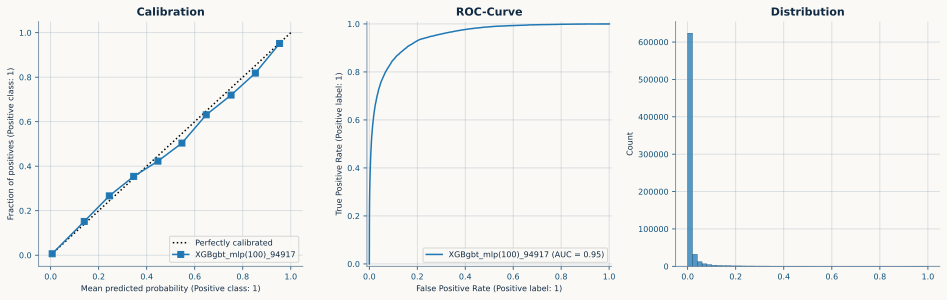

In [43]:
## -- Plot oof distributions --
_, axs = plt.subplots(1, 3, figsize=(13, 4))

CalibrationDisplay.from_predictions(y, oof_preds, n_bins=10, name=n, ax=axs[0])
axs[0].set_title(f"Calibration")

RocCurveDisplay.from_predictions(y, oof_preds, name=n, ax=axs[1])
axs[1].set_title(f"ROC-Curve")

sns.histplot(oof_preds, ax=axs[2], bins=50)
axs[2].set_title(f"Distribution")

plt.tight_layout(pad=0.2)
plt.show()

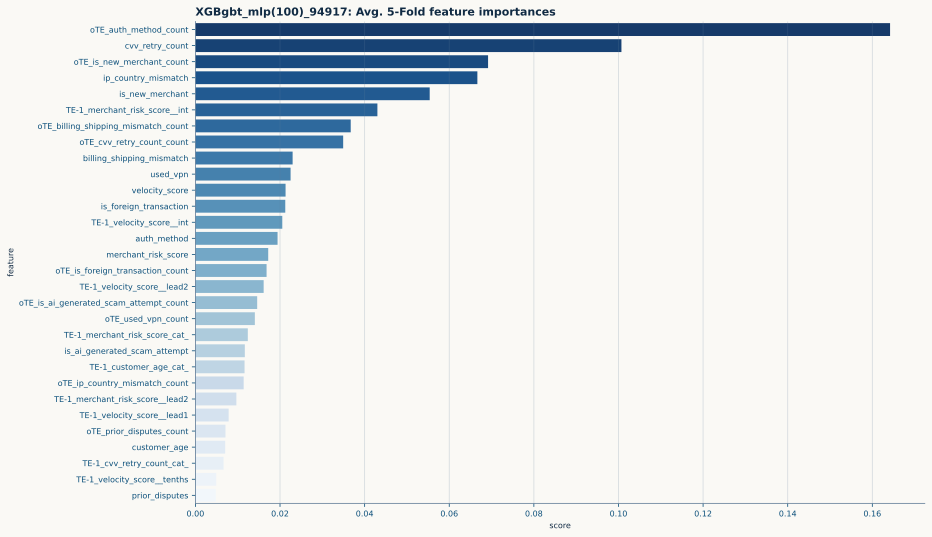

In [44]:
## -- Get model feature importances --
top_n = 30

fi_df = pd.DataFrame({"feature": feat_names, "score": np.mean(feat_importances, axis=0),})\
          .sort_values(by="score", ascending=False).reset_index(drop=True)

plt.figure(figsize=(13, top_n*0.25))
sns.barplot(data=fi_df.head(top_n), x="score", y="feature", palette='Blues_r')

plt.title(f"{n}: Avg. {FOLDS}-Fold feature importances", loc='left')
plt.tight_layout()
plt.show()

print()

In [50]:
# try:
#     import shap
# except:
#     !uv pip install -q shap
#     import shap

# print(f"Shap version: {shap.__version__}")

In [49]:
# print(f"Model pipeline features: {len(feat_names)}")

# # Randomly select 100 rows without replacement
# rng = np.random.default_rng(seed=139)
# indices = rng.choice(X_val.shape[0], size=100, replace=False)
# val_x = X_val.to_numpy()[indices]
# val_y = y_val.to_numpy()[indices]

# ## -- Shap Explainer --
# def f(x):
#     return model.predict_proba(x)[:, 1]

# val_y

In [48]:
# _id = 0
# MAX = 20

# explainer   = shap.Explainer(f, val_x, feature_names=feat_names, seed=42)
# explanation = explainer(val_x, max_evals=max(500, 2*val_x.shape[1]+1))

# ## -- Bar plot --
# plt.subplot(121)
# shap.plots.bar(explanation[_id], max_display=MAX, show=False)
# plt.title(f"Impact on model predictions for label {val_y[_id]}")

# ## -- Beeswarm plot --
# plt.subplot(122)
# shap.plots.beeswarm(
#     explanation,
#     order=explanation.abs.max(0),
#     plot_size=(13, 8),
#     max_display=MAX,
#     color_bar=False,
#     show=False,
# )

# plt.title("Beeswarm - Most impactful features")
# plt.suptitle(f"{n}: SHAP Explainer", size=12, weight="semibold", color=CRIM)
# plt.tight_layout(pad=1.5)
# plt.show()

# print()